In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# load the dataset
df = pd.read_csv("../dataset/beginner_sales_dirty_dataset.csv")

In [3]:
#First 5 rows
df.head()

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Discount,Payment_Mode
0,ORD1001,2025-05-21,Sana,Mumbai,Monitor,Electronics,1.0,10718.79,0.05,Card
1,ORD1002,2025-08-05,Priya,Pune,Monitor,Electronics,5.0,10951.02,0.00,UPI
2,ORD1003,2025-10-15,Dev,Mumbai,Mobile,Electronics,5.0,22673.32,0.05,Net Banking
3,ORD1004,2025-01-04,Ishita,Mumbai,Mouse,Accessories,3.0,710.34,0.10,Net Banking
4,ORD1005,2025-06-22,Sana,Pune,Mobile,Electronics,2.0,25017.61,0.15,UPI


In [4]:
# last 5 rows
df.tail(5)

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Discount,Payment_Mode
503,ORD1033,2025-10-24,Aarav,Aurangabad,Headphones,Accessories,2.0,2053.10,0.10,UPI
504,ORD1461,2025-02-21,Kabir,Pune,Mouse,Accessories,5.0,666.12,0.10,UPI
505,ORD1156,2025-11-11,Aarav,NaN,Keyboard,Accessories,5.0,1099.76,0.15,Cash
506,ORD1250,2025-10-09,Sana,Nashik,Keyboard,Accessories,5.0,1182.13,0.05,UPI
507,ORD1218,2025-07-08,Meera,Kolhapur,Mobile,Electronics,4.0,23267.65,0.00,Cash


In [5]:
# total rows and colum
df.shape

(508, 10)

In [6]:
# colum name
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_Name', 'City', 'Product',
       'Category', 'Quantity', 'Unit_Price', 'Discount', 'Payment_Mode'],
      dtype='str')

In [7]:
# datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       508 non-null    str    
 1   Order_Date     508 non-null    str    
 2   Customer_Name  494 non-null    str    
 3   City           490 non-null    str    
 4   Product        508 non-null    str    
 5   Category       508 non-null    str    
 6   Quantity       496 non-null    float64
 7   Unit_Price     498 non-null    float64
 8   Discount       508 non-null    float64
 9   Payment_Mode   508 non-null    str    
dtypes: float64(3), str(7)
memory usage: 65.4 KB


In [8]:
# statistical summary
df.describe(include='all')

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Discount,Payment_Mode
count,508,508,494,490,508,508,496.000000,498.000000,508.000000,508
unique,500,289,8,11,11,5,NaN,NaN,NaN,9
top,ORD1014,2025-08-05,Sana,Aurangabad,Headphones,Electronics,NaN,NaN,NaN,UPI
freq,2,5,69,80,76,273,NaN,NaN,NaN,137
mean,NaN,NaN,NaN,NaN,NaN,NaN,3.693548,16075.644036,0.094094,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,7.573668,18663.223751,0.181258,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,-1.000000,-500.000000,-0.200000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,1278.900000,0.050000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,11867.395000,0.100000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,21222.580000,0.150000,NaN


In [9]:
# missing values
df.isnull().sum()

Order_ID          0
Order_Date        0
Customer_Name    14
City             18
Product           0
Category          0
Quantity         12
Unit_Price       10
Discount          0
Payment_Mode      0
dtype: int64

In [10]:
# duplicates values
df.duplicated().sum()

np.int64(8)

##  Data Cleaning

In [11]:
## Missing Values
df.isnull().sum()

Order_ID          0
Order_Date        0
Customer_Name    14
City             18
Product           0
Category          0
Quantity         12
Unit_Price       10
Discount          0
Payment_Mode      0
dtype: int64

In [12]:
# missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Order_ID         0.000000
Order_Date       0.000000
Customer_Name    2.755906
City             3.543307
Product          0.000000
Category         0.000000
Quantity         2.362205
Unit_Price       1.968504
Discount         0.000000
Payment_Mode     0.000000
dtype: float64


In [13]:
# dupliacted value check
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
503     True
504     True
505     True
506     True
507     True
Length: 508, dtype: bool

In [14]:
#remove duplicates
df=df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [15]:
# Text cleaning
df["City"] = df["City"].str.strip().str.title()

df["Product"] = df["Product"].str.strip().str.title()

df["Payment_Mode"] = df["Payment_Mode"].str.strip().str.title()

df["Customer_Name"] = df["Customer_Name"].str.strip().str.title()

In [16]:
#check
print(df["City"].unique())
print(df["Product"].unique())
print(df["Payment_Mode"].unique())

<ArrowStringArray>
['Mumbai', 'Pune', 'Aurangabad', 'Kolhapur', nan, 'Nashik', 'Nagpur']
Length: 7, dtype: str
<ArrowStringArray>
['Monitor', 'Mobile', 'Mouse', 'Headphones', 'Laptop', 'Keyboard', 'Tablet']
Length: 7, dtype: str
<ArrowStringArray>
['Card', 'Upi', 'Net Banking', 'Cash']
Length: 4, dtype: str


In [17]:
#Date format clean
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

In [18]:
#check
df['Order_Date'].dtype

dtype('<M8[us]')

In [19]:
#Numeric colum clean
# check invalid column
print(df[df["Quantity"] <= 0])
print(df[df["Unit_Price"] <= 0])
print(df[(df["Discount"] < 0) | (df["Discount"] > 1)])

    Order_ID Order_Date Customer_Name        City     Product     Category  \
22   ORD1023 2025-11-10          Sana      Mumbai      Laptop  electronics   
44   ORD1045 2025-12-20         Rohan      Mumbai      Laptop  Electronics   
243  ORD1244 2025-10-23         Rohan  Aurangabad      Mobile  Electronics   
262  ORD1263 2025-05-21         Meera      Nashik  Headphones  Accessories   

     Quantity  Unit_Price  Discount Payment_Mode  
22        0.0    47097.07      0.00         Card  
44       -1.0    62343.34      0.10          Upi  
243       0.0    24068.95      0.05         Cash  
262       0.0     1718.35      0.15          Upi  
    Order_ID Order_Date Customer_Name      City     Product     Category  \
120  ORD1121 2025-06-10         Priya    Nagpur  Headphones  Accessories   
164  ORD1165 2025-04-19          Sana    Mumbai  Headphones  Accessories   
309  ORD1310 2025-07-10         Aarav    Nagpur     Monitor  Electronics   
459  ORD1460 2025-03-08         Rohan      Pune   

In [20]:
#change invalid to Nan
df.loc[df["Quantity"] <= 0, "Quantity"] = np.nan

df.loc[df["Unit_Price"] <= 0, "Unit_Price"] = np.nan

df.loc[
    (df["Discount"] < 0) | (df["Discount"] > 1),
    "Discount"
] = np.nan

In [21]:
# handle missing values
df["City"] = df["City"].fillna(df["City"].mode()[0])

df["Customer_Name"] = df["Customer_Name"].fillna("Unknown")

df["Quantity"] = df["Quantity"].fillna(
    df["Quantity"].median()
)

df["Unit_Price"] = df["Unit_Price"].fillna(
    df.groupby("Product")["Unit_Price"].transform("median")
)

df["Discount"] = df["Discount"].fillna(
    df["Discount"].median()
)

In [22]:
# category correction
category_mapping = {
    "Laptop": "Electronics",
    "Mobile": "Electronics",
    "Headphones": "Accessories",
    "Keyboard": "Accessories",
    "Mouse": "Accessories",
    "Monitor": "Electronics",
    "Tablet": "Electronics"
}

df["Category"] = df["Product"].map(category_mapping)

In [24]:
# final data quality check
print("Missing Values:")
print(df.isnull().sum())

print("Duplicates:")
print(df.duplicated().sum())

print("Dataset Shape:")
print(df.shape)

print(df.info())

Missing Values:
Order_ID         0
Order_Date       0
Customer_Name    0
City             0
Product          0
Category         0
Quantity         0
Unit_Price       0
Discount         0
Payment_Mode     0
dtype: int64
Duplicates:
0
Dataset Shape:
(500, 10)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       500 non-null    str           
 1   Order_Date     500 non-null    datetime64[us]
 2   Customer_Name  500 non-null    str           
 3   City           500 non-null    str           
 4   Product        500 non-null    str           
 5   Category       500 non-null    str           
 6   Quantity       500 non-null    float64       
 7   Unit_Price     500 non-null    float64       
 8   Discount       500 non-null    float64       
 9   Payment_Mode   500 non-null    str           
dtypes: datetime64[us](1), float64(3

In [25]:
#save dataset
df.to_csv(
    "../output/cleaned_sales_data.csv",
    index=False
)

In [26]:
# feature engineering
# load cleaned dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../output/cleaned_sales_data.csv"
)

df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [27]:
#Revenue Column create
df["Revenue"] = (
    df["Quantity"] *
    df["Unit_Price"] *
    (1 - df["Discount"])
)

print(df[["Product", "Quantity", "Revenue"]].head())

   Product  Quantity      Revenue
0  Monitor       1.0   10182.8505
1  Monitor       5.0   54755.1000
2   Mobile       5.0  107698.2700
3    Mouse       3.0    1917.9180
4   Mobile       2.0   42529.9370


In [28]:
#create month colum
df["Month"] = df["Order_Date"].dt.month_name()

df["Year"] = df["Order_Date"].dt.year

df["Month_Number"] = df["Order_Date"].dt.month

In [29]:
#Average Order Value (AOV)
total_revenue = df["Revenue"].sum()

total_orders = df["Order_ID"].nunique()

aov = total_revenue / total_orders

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Average Order Value:", aov)

Total Revenue: 30526027.117
Total Orders: 500
Average Order Value: 61052.054233999996


### EDA 

In [30]:
#Total Revenue
print("Total Revenue:", df["Revenue"].sum())

Total Revenue: 30526027.117


In [31]:
#totel orders
print("Total Orders:", df["Order_ID"].nunique())

Total Orders: 500


In [32]:
# best selling product
best_product = (
    df.groupby("Product")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(best_product)

Product
Laptop        348.0
Headphones    346.0
Mobile        326.0
Mouse         224.0
Keyboard      220.0
Tablet        195.0
Monitor       188.0
Name: Quantity, dtype: float64


In [33]:
# highest revenue city
city_revenue = (
    df.groupby("City")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(city_revenue)

City
Aurangabad    1.029738e+07
Pune          5.698726e+06
Mumbai        4.348687e+06
Nagpur        3.783016e+06
Nashik        3.596514e+06
Kolhapur      2.801704e+06
Name: Revenue, dtype: float64


In [34]:
#category wise revenue
category_sales = (
    df.groupby("Category")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Category
Electronics    2.910697e+07
Accessories    1.419056e+06
Name: Revenue, dtype: float64


In [35]:
#payment mode analysis
payment_analysis = (
    df.groupby("Payment_Mode")["Order_ID"]
    .nunique()
    .sort_values(ascending=False)
)

print(payment_analysis)

Payment_Mode
Upi            150
Net Banking    123
Card           116
Cash           111
Name: Order_ID, dtype: int64


In [36]:
#monthly revenue analysis
monthly_sales = (
    df.groupby(["Year", "Month_Number"])["Revenue"]
    .sum()
    .reset_index()
)

print(monthly_sales)

    Year  Month_Number       Revenue
0   2025             1  1.806281e+06
1   2025             2  3.760605e+06
2   2025             3  2.291321e+06
3   2025             4  1.849286e+06
4   2025             5  1.882860e+06
5   2025             6  2.212355e+06
6   2025             7  1.627112e+06
7   2025             8  1.385032e+06
8   2025             9  1.100323e+06
9   2025            10  2.200450e+06
10  2025            11  8.279065e+06
11  2025            12  2.131338e+06


In [37]:
#top 5 customers
top_customers = (
    df.groupby("Customer_Name")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print(top_customers)

Customer_Name
Rohan    1.011219e+07
Sana     3.996331e+06
Dev      3.185646e+06
Aarav    3.061683e+06
Meera    2.792113e+06
Name: Revenue, dtype: float64


In [38]:
# save analysis dataset
df.to_csv(
    "../output/sales_analysis_data.csv",
    index=False
)

print("Analysis Dataset Saved Successfully!")

Analysis Dataset Saved Successfully!


## Business Report

In [39]:
#Q1. What is the Total Sales?
total_sales = (df["Quantity"] * df["Unit_Price"]).sum()

print("Total Sales:", total_sales)

Total Sales: 33536091.02


In [40]:
#Q2. What is the Total Number of Orders?


total_orders = df["Order_ID"].nunique()

print("Total Orders:", total_orders)

Total Orders: 500


In [41]:
#Q3. Which Product Has the Highest Sales Quantity?

product_sales = df.groupby("Product")["Quantity"].sum()

best_product = product_sales.idxmax()

print("Best Selling Product:", best_product)
print(product_sales.sort_values(ascending=False))

Best Selling Product: Laptop
Product
Laptop        348.0
Headphones    346.0
Mobile        326.0
Mouse         224.0
Keyboard      220.0
Tablet        195.0
Monitor       188.0
Name: Quantity, dtype: float64


In [42]:
#Q4. Which City Has the Highest Number of Orders?


city_orders = df.groupby("City")["Order_ID"].nunique()

top_city = city_orders.idxmax()

print("Top City:", top_city)
print(city_orders.sort_values(ascending=False))

Top City: Pune
City
Pune          108
Nashik         87
Mumbai         82
Aurangabad     78
Kolhapur       75
Nagpur         70
Name: Order_ID, dtype: int64


In [44]:
#Q5. Which Category Has the Highest Sales Quantity?


category_sales = df.groupby("Category")["Quantity"].sum()

best_category = category_sales.idxmax()

print("Best Selling Category:", best_category)
print(category_sales.sort_values(ascending=False))

Best Selling Category: Electronics
Category
Electronics    1057.0
Accessories     790.0
Name: Quantity, dtype: float64


In [45]:
#Q6. Which Payment Mode Is Most Preferred by Customers?

payment_analysis = df.groupby("Payment_Mode")["Order_ID"].nunique()

best_payment = payment_analysis.idxmax()

print("Most Preferred Payment Mode:", best_payment)
print(payment_analysis.sort_values(ascending=False))

Most Preferred Payment Mode: Upi
Payment_Mode
Upi            150
Net Banking    123
Card           116
Cash           111
Name: Order_ID, dtype: int64


In [47]:
#Q7. Which Month Has the Highest Number of Orders?

df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Month"] = df["Order_Date"].dt.month_name()

monthly_orders = df.groupby("Month")["Order_ID"].nunique()

best_month = monthly_orders.idxmax()

print("Best Month:", best_month)
print(monthly_orders.sort_values(ascending=False))

Best Month: July
Month
November     46
July         46
February     45
May          45
June         43
April        42
October      41
March        41
January      40
August       40
December     38
September    33
Name: Order_ID, dtype: int64


In [48]:
#Q8. Who Are the Top 5 Customers Based on Number of Orders?


top_customers = (
    df.groupby("Customer_Name")["Order_ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 Customers:")
print(top_customers)

Top 5 Customers:
Customer_Name
Sana     68
Aarav    65
Meera    65
Rohan    64
Dev      59
Name: Order_ID, dtype: int64


In [49]:
#Q9. Which City Generates the Highest Revenue?

df["Revenue"] = (
    df["Quantity"] *
    df["Unit_Price"] *
    (1 - df["Discount"])
)

city_revenue = df.groupby("City")["Revenue"].sum()

top_revenue_city = city_revenue.idxmax()

print("Highest Revenue City:", top_revenue_city)
print(city_revenue.sort_values(ascending=False))

Highest Revenue City: Aurangabad
City
Aurangabad    1.029738e+07
Pune          5.698726e+06
Mumbai        4.348687e+06
Nagpur        3.783016e+06
Nashik        3.596514e+06
Kolhapur      2.801704e+06
Name: Revenue, dtype: float64


In [50]:
#Q10. What Is the Average Order Value (AOV)?

total_revenue = df["Revenue"].sum()

total_orders = df["Order_ID"].nunique()

aov = total_revenue / total_orders

print("Average Order Value:", round(aov, 2))

Average Order Value: 61052.05


In [51]:
#Final Business Analysis Summary
print("========== SALES ANALYSIS REPORT ==========")

print("Total Sales:", round(total_sales, 2))

print("Total Orders:", total_orders)

print("Best Selling Product:", best_product)

print("Top City by Orders:", top_city)

print("Best Category:", best_category)

print("Most Preferred Payment:", best_payment)

print("Best Sales Month:", best_month)

print("Highest Revenue City:", top_revenue_city)

print("Average Order Value:", round(aov, 2))

print("===========================================")

========== SALES ANALYSIS REPORT ==========
Total Sales: 33536091.02
Total Orders: 500
Best Selling Product: Laptop
Top City by Orders: Pune
Best Category: Electronics
Most Preferred Payment: Upi
Best Sales Month: July
Highest Revenue City: Aurangabad
Average Order Value: 61052.05


### Business Insights
Based on the data analysis, the following business insights can be identified:

1. Best Product: The product with the highest total sales quantity is the most demanded product among customers.

2. Top City: The city generating the highest revenue is the best-performing city and should receive more business focus.

3. Payment Mode: The payment method with the highest number of orders is the most preferred payment method among customers

4. Monthly Orders: The month with the highest number of orders indicates the period of highest customer demand

5. Top Customers: The top 5 customers based on order count are the most frequent customers of the business.

6. Category Analysis: The category generating the highest revenue contributes the most to overall business sales.

7. Revenue Analysis: Total revenue represents the overall sales income generated by the business after discounts.

8. Average Order Value: AOV represents the average revenue generated from each order.

##  Sales Dashboard Using Matplotlib

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../output/sales_analysis_data.csv")

df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [53]:
# KPI Calculations
total_revenue = df["Revenue"].sum()

total_orders = df["Order_ID"].nunique()

average_order_value = total_revenue / total_orders

total_quantity = df["Quantity"].sum()

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Average Order Value:", average_order_value)
print("Total Quantity:", total_quantity)

Total Revenue: 30526027.117
Total Orders: 500
Average Order Value: 61052.054233999996
Total Quantity: 1847.0


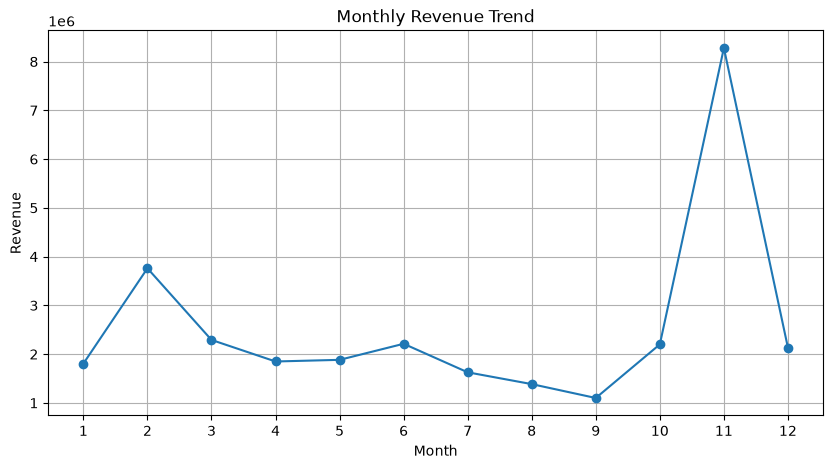

In [54]:
#Monthly Revenue Line Chart
monthly_sales = (
    df.groupby(df["Order_Date"].dt.month)["Revenue"]
    .sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

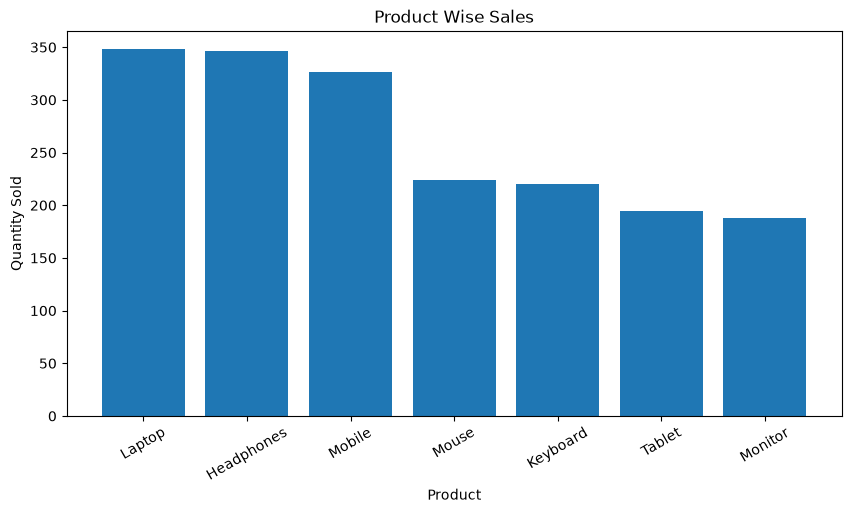

In [55]:
#Product-wise Sales Bar Chart
product_sales = (
    df.groupby("Product")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

plt.bar(
    product_sales.index,
    product_sales.values
)

plt.title("Product Wise Sales")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=30)
plt.show()

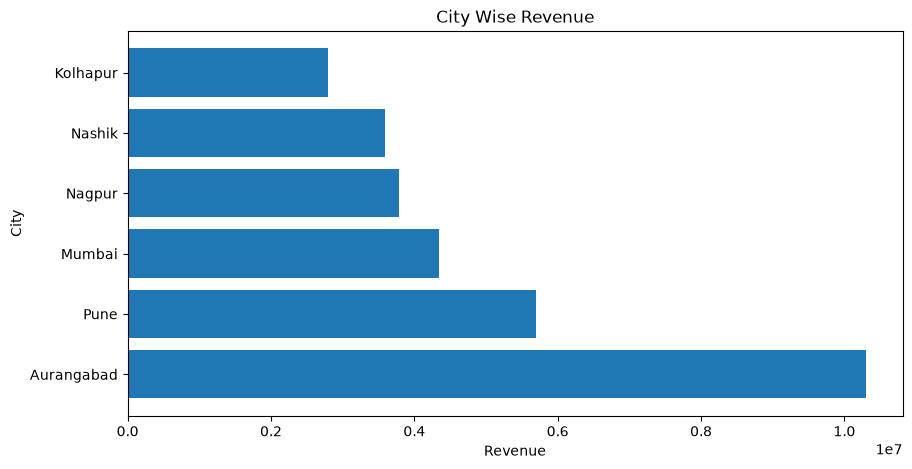

In [56]:
# City-wise Revenue Chart

city_sales = (
    df.groupby("City")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

plt.barh(
    city_sales.index,
    city_sales.values
)

plt.title("City Wise Revenue")
plt.xlabel("Revenue")
plt.ylabel("City")

plt.show()


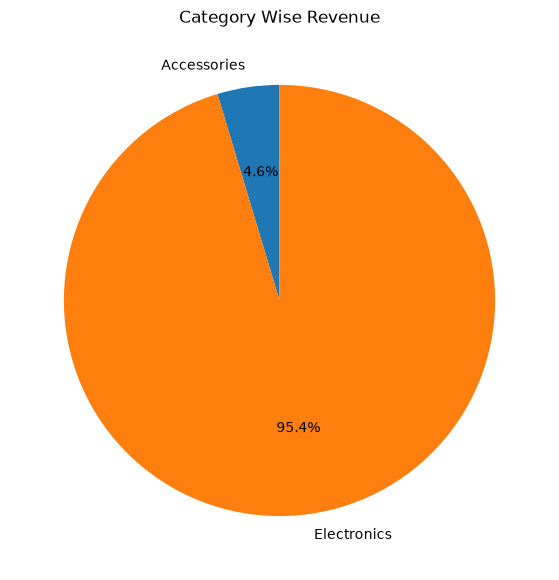

In [57]:
# Category-wise Revenue Pie Chart
category_sales = (
    df.groupby("Category")["Revenue"]
    .sum()
)

plt.figure(figsize=(7, 7))

plt.pie(
    category_sales.values,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category Wise Revenue")

plt.show()

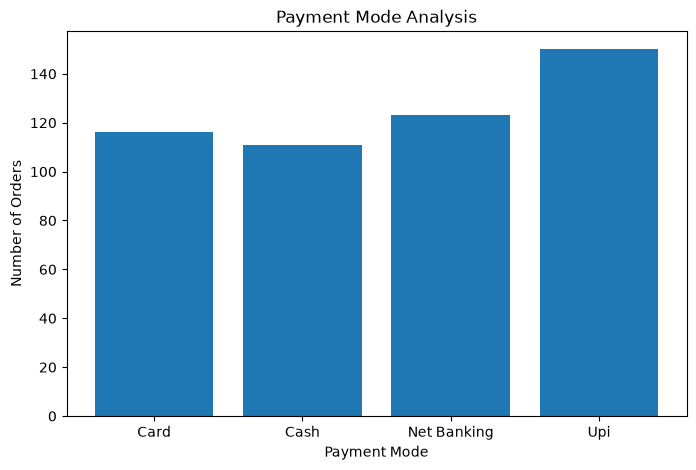

In [58]:
#Payment Mode Analysis
payment_sales = (
    df.groupby("Payment_Mode")["Order_ID"]
    .nunique()
)

plt.figure(figsize=(8, 5))

plt.bar(
    payment_sales.index,
    payment_sales.values
)

plt.title("Payment Mode Analysis")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")

plt.show()

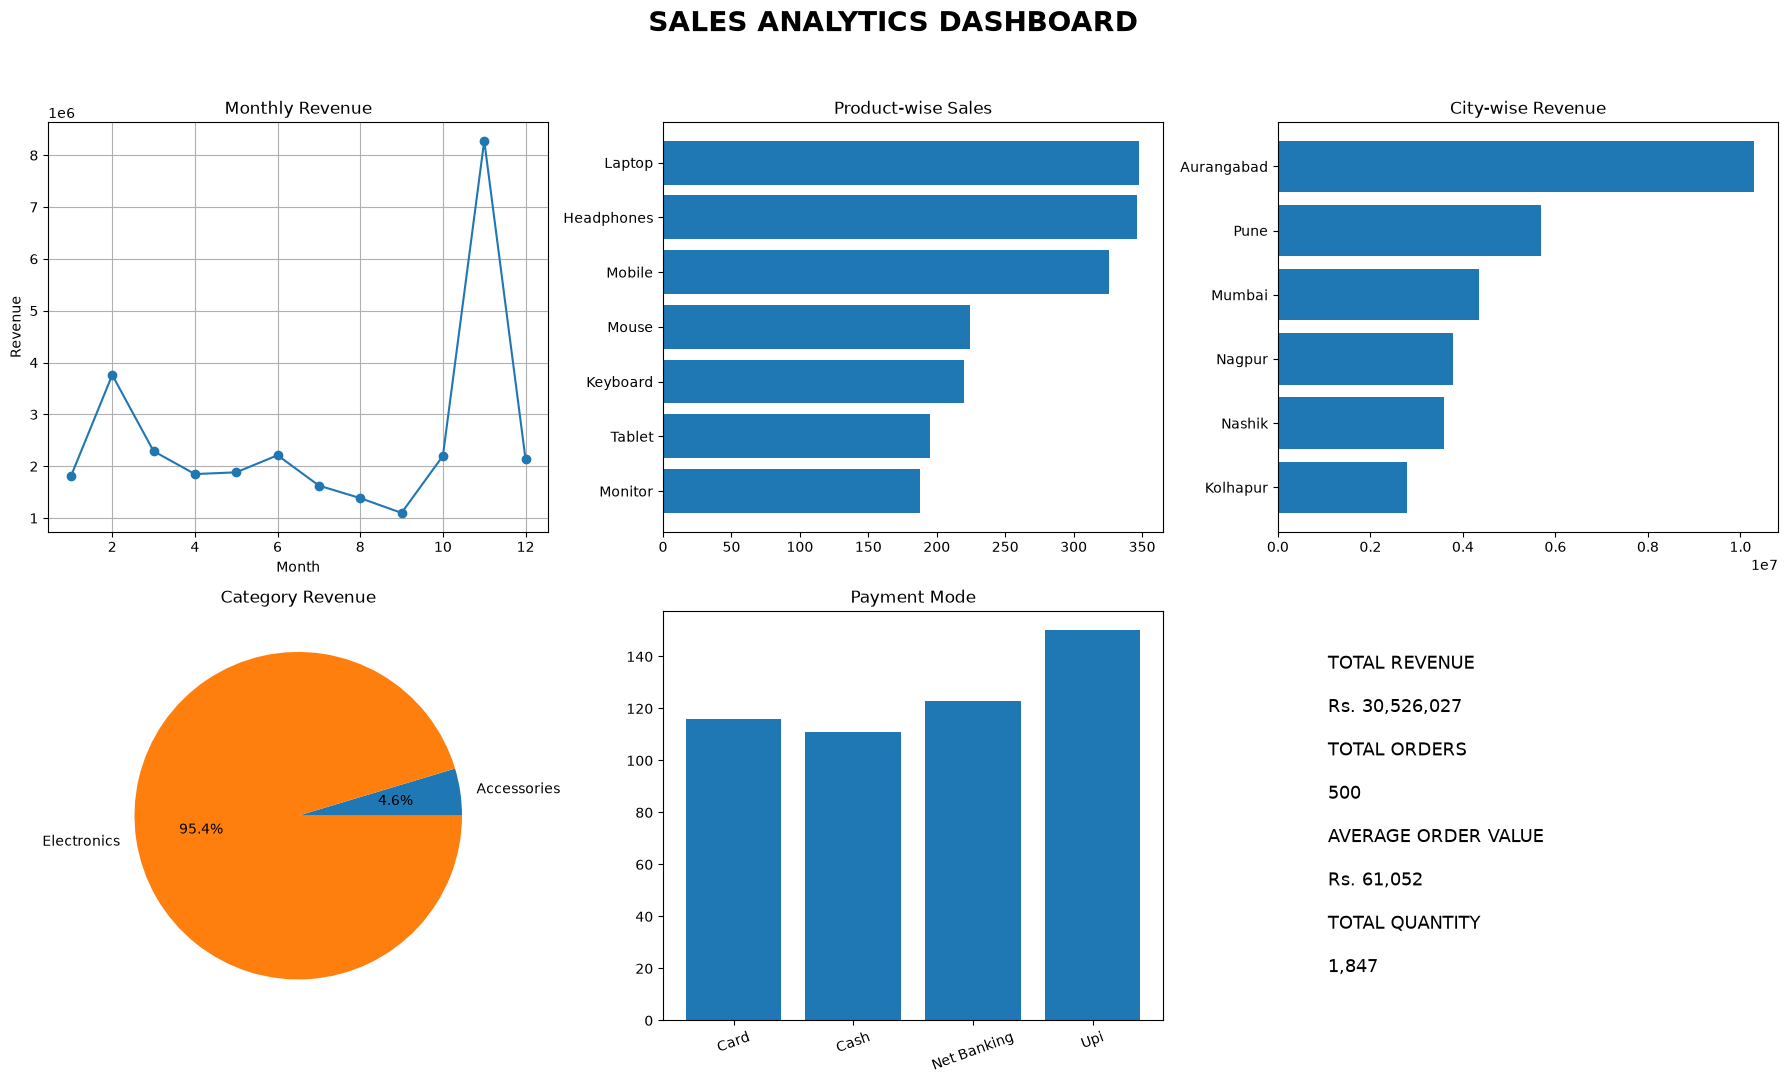

In [59]:
#Combine Everything into One Dashboard
fig, ax = plt.subplots(2, 3, figsize=(18, 11))

fig.suptitle(
    "SALES ANALYTICS DASHBOARD",
    fontsize=20,
    fontweight="bold"
)

# 1. Monthly Revenue
monthly = df.groupby(
    df["Order_Date"].dt.month
)["Revenue"].sum()

ax[0, 0].plot(monthly.index, monthly.values, marker="o")
ax[0, 0].set_title("Monthly Revenue")
ax[0, 0].set_xlabel("Month")
ax[0, 0].set_ylabel("Revenue")
ax[0, 0].grid(True)

# 2. Product Sales
product = df.groupby("Product")["Quantity"].sum().sort_values()

ax[0, 1].barh(product.index, product.values)
ax[0, 1].set_title("Product-wise Sales")

# 3. City Revenue
city = df.groupby("City")["Revenue"].sum().sort_values()

ax[0, 2].barh(city.index, city.values)
ax[0, 2].set_title("City-wise Revenue")

# 4. Category Revenue
category = df.groupby("Category")["Revenue"].sum()

ax[1, 0].pie(
    category.values,
    labels=category.index,
    autopct="%1.1f%%"
)
ax[1, 0].set_title("Category Revenue")

# 5. Payment Mode
payment = df.groupby("Payment_Mode")["Order_ID"].nunique()

ax[1, 1].bar(payment.index, payment.values)
ax[1, 1].set_title("Payment Mode")
ax[1, 1].tick_params(axis="x", rotation=20)

# 6. KPI Summary
ax[1, 2].axis("off")

kpi_text = f"""
TOTAL REVENUE

Rs. {total_revenue:,.0f}

TOTAL ORDERS

{total_orders}

AVERAGE ORDER VALUE

Rs. {average_order_value:,.0f}

TOTAL QUANTITY

{total_quantity:,.0f}
"""

ax[1, 2].text(
    0.1, 0.5,
    kpi_text,
    fontsize=13,
    verticalalignment="center"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "../output/sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
df.to_csv(
    "Final_Cleaned_Sales_Data.csv",
    index=False
)

print("Dataset Exported Successfully!")

Dataset Exported Successfully!
